# 05 · Stage 5: M3, regimes, regressions, placebo, robustness (spec §7–§8)

**Gate:** tables + explain-back in the learning chat. This notebook holds the tables; the explain-back is yours.

**What this stage delivers**
1. **Bond-level evidence (decision #17).**
   - **M3**: the auctioned gilt's residual (market yield − model yield) from T-10 to T+10, with the same three numbers.
   - **M1b** extended back to 1999.
   - Before 25 Nov 2002 the DMO published no yields, so the market yield is computed with our pricer from the DMO **clean price** plus our accrued interest. It reproduces the DMO yields 2003–2017 to 0.0001bp (§1).
2. **Control C** for M2: the change in the gilt − OIS spread at the gilt's maturity, for auctions from Dec 2021 (`ois.py`).
3. **Inference** (`inference.py`): OLS with standard errors clustered by auction week, plus Newey-West in calendar time (30-day Bartlett) as a check. Both reproduce statsmodels exactly (`tests/test_stage5.py`).
4. **Regressions** per spec §8 and decision #17 (`analysis.py`):
   - M1b (1999–2017);
   - M1 with **gilt fixed effects** for 2018–2026;
   - M2 (B-β) three numbers, all years;
   - M3 three numbers, 1999–2017;
   - M1 pooled on the M1b sample, for the M1b vs M1 comparison;
   - an extra H4 specification.
5. **Placebo** (`placebo.py`): 1,000 draws of non-auction dates for the same gilt in the same bucket. M2 and M3 are recomputed exactly; the engine reproduces the real auctions to < 1e-8.
6. **Robustness:** drop the LDI window; drop Feb–Oct 2022; drop > 5y beyond the curve; controls B and C; DV01 incl. PAOF; volatility at 10y; conventional-only syndications and tenders; looser M1b rules.

**Choices the spec leaves open (proposed; ⚑, listed at the gate in §9):**
- cover surprise uses the previous **5** auctions of the same bucket;
- syndication and tender controls are **dummies** (any within ±5 business days);
- H4's "post-2022" starts at **1 Nov 2022** (active QT);
- the Newey-West bandwidth is **30 calendar days**;
- in the placebo design, the **same gilt** is used on a random date, **in the same bucket**, more than 10 business days from its own auctions;
- control C extrapolates the OIS curve **flat-forward beyond 25y**.

Signs: every number is a yield change in bp. **Positive = the gilt cheapened** (its yield rose against the curve or control).

In [1]:
import datetime as dt
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import seaborn as sns

from gilt_study import analysis as an, auctions as au, inference as inf, measures as ms, ois, placebo as pl, plotting

warnings.filterwarnings("ignore")
pd.set_option("display.width", 230); pd.set_option("display.max_rows", 300); pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", 60)
plotting.set_seaborn_theme()
A = an.dataset()
OUT = an.main()            # writes data/processed_data/stage5/*.csv
print(f"{len(A)} auctions; M1b {A.m1b_bp.notna().sum()}, M3 (day) {A.m3_day_bp.notna().sum()}, control C (day) {A.m2_day_c_bp.notna().sum()}")

912 auctions; M1b 319, M3 (day) 417, control C (day) 241


## 1. Market yields before Nov 2002, M1b back to 1999, and M3 coverage

In [2]:
P = au.load_auction_panel()
MY = ms.load_market_yields()
print(MY.yield_source.value_counts().to_string(), "\nfrom-clean dates:", MY.loc[MY.yield_source == ms.SRC_FROM_CLEAN, "date"].min(),
      "to", MY.loc[MY.yield_source == ms.SRC_FROM_CLEAN, "date"].max())
# check the method where the DMO did publish yields: the yield from the DMO clean price vs the DMO yield
T = P.groupby("isin").agg(maturity=("maturity", "first"), coupon=("coupon", "first"), fi=("first_issue", "first"), fc=("first_coupon", "first"))
S = MY[(MY.yield_source == ms.SRC_DMO_YIELD) & (MY.dmo_yield > 0)].sample(3000, random_state=1)
dd = lambda v: v if isinstance(v, dt.date) else None
got = ms._yields_from_clean(([(i, d, float(c), T.at[i, "maturity"], T.at[i, "coupon"], dd(T.at[i, "fi"]), dd(T.at[i, "fc"]))
                              for i, d, c in zip(S["isin"], S["date"], S["clean"])],))
diff = 100 * (np.array([g[2] for g in got]) - S["dmo_yield"].to_numpy())
print(f"\nyield from DMO clean price - DMO yield, 3,000 random gilt-days 2002-2017: max |diff| {np.nanmax(np.abs(diff)):.5f} bp")
M = ms.load_measures()
print("\nM1b:", int(M.m1b_bp.notna().sum()), "auctions; earliest", M.loc[M.m1b_bp.notna(), "auction_date"].min())
print("M3 three numbers available:", M[["m3_pre_bp", "m3_day_bp", "m3_post_bp"]].notna().sum().to_dict(),
      "(new issues have no pre-auction prices; the series ends 21 Jul 2017)")

yield_source
DMO yield               100328
from DMO clean price      4454 
from-clean dates: 1998-11-02 to 2002-11-22



yield from DMO clean price - DMO yield, 3,000 random gilt-days 2002-2017: max |diff| 0.00006 bp

M1b: 319 auctions; earliest 1999-05-26
M3 three numbers available: {'m3_pre_bp': 395, 'm3_day_bp': 417, 'm3_post_bp': 416} (new issues have no pre-auction prices; the series ends 21 Jul 2017)


- **The clean-price method is exact where it can be checked.** Where the DMO did publish yields, our pricer reproduces them from the DMO clean price to 0.0001bp.
- **M1b grows from 309 to 319 auctions** (back to 26 May 1999).
- **M3 covers about 400 auctions, 1999–2017.** The pre-auction number needs a price at T-6, so new issues have only the day and post numbers.

## 2. The headline: the PM's three numbers

Means with standard errors clustered by auction week (Newey-West as a check). M2 covers all years. M3 and M1b run to 2017 (bond prices).

In [3]:
H = OUT["headline"]
def show(set_, by):
    t = H[(H["set"] == set_) & (H["by"] == by)].copy()
    t["mean (bp)"] = t["mean_bp"].map("{:+.2f}".format)
    t["95% CI"] = [f"[{m - 1.96 * s:+.2f}, {m + 1.96 * s:+.2f}]" for m, s in zip(t.mean_bp, t.se_cluster)]
    return t[["group", "measure", "n", "mean (bp)", "95% CI", "p_cluster", "p_nw", "clusters"]].round({"p_cluster": 3, "p_nw": 3})
show("M2 (B-β), all years", "all")

,group,measure,n,mean (bp),95% CI,p_cluster,p_nw,clusters
0,all,pre,912.0,+0.43,"[+0.10, +0.77]",0.012,0.006,723.0
1,all,day,912.0,+0.04,"[-0.12, +0.19]",0.634,0.627,723.0
2,all,post,912.0,-0.43,"[-0.74, -0.13]",0.006,0.003,723.0


In [4]:
show("M2 (B-β), all years", "bucket")

,group,measure,n,mean (bp),95% CI,p_cluster,p_nw,clusters
3,short,pre,324.0,+0.45,"[-0.42, +1.31]",0.310,0.276,315.0
4,short,day,324.0,+0.15,"[-0.23, +0.52]",0.451,0.462,315.0
5,short,post,324.0,-0.68,"[-1.40, +0.05]",0.068,0.060,315.0
6,medium,pre,289.0,+0.36,"[-0.05, +0.76]",0.084,0.088,288.0
7,medium,day,289.0,+0.03,"[-0.16, +0.22]",0.753,0.721,288.0
8,medium,post,289.0,-0.31,"[-0.70, +0.08]",0.122,0.113,288.0
9,long,pre,299.0,+0.48,"[+0.04, +0.92]",0.032,0.022,297.0
10,long,day,299.0,-0.08,"[-0.27, +0.12]",0.453,0.430,297.0
11,long,post,299.0,-0.28,"[-0.67, +0.10]",0.152,0.124,297.0


In [5]:
show("M3, 1999-2017", "all")

,group,measure,n,mean (bp),95% CI,p_cluster,p_nw,clusters
24,all,pre,395.0,+0.37,"[+0.18, +0.56]",0.00,0.002,361.0
25,all,day,417.0,-0.32,"[-0.43, -0.21]",0.00,0.000,381.0
26,all,post,416.0,-0.18,"[-0.31, -0.04]",0.01,0.011,380.0


In [6]:
show("M3, 1999-2017", "bucket")

,group,measure,n,mean (bp),95% CI,p_cluster,p_nw,clusters
27,short,pre,127.0,+0.51,"[+0.12, +0.91]",0.011,0.027,126.0
28,short,day,137.0,-0.50,"[-0.77, -0.23]",0.000,0.001,136.0
29,short,post,136.0,-0.39,"[-0.65, -0.13]",0.004,0.005,135.0
30,medium,pre,122.0,+0.40,"[+0.14, +0.66]",0.003,0.002,122.0
31,medium,day,127.0,-0.26,"[-0.42, -0.09]",0.003,0.004,127.0
32,medium,post,127.0,-0.27,"[-0.52, -0.02]",0.039,0.038,127.0
33,long,pre,146.0,+0.21,"[-0.10, +0.53]",0.186,0.180,146.0
34,long,day,153.0,-0.22,"[-0.32, -0.11]",0.000,0.000,153.0
35,long,post,153.0,+0.09,"[-0.08, +0.26]",0.317,0.292,153.0


In [7]:
show("Levels to 2017", "all")

,group,measure,n,mean (bp),95% CI,p_cluster,p_nw,clusters
48,all,M1b,319.0,+1.39,"[+0.96, +1.82]",0.0,0.0,295.0
49,all,M1 (same auctions),319.0,+1.92,"[+1.26, +2.57]",0.0,0.0,295.0


In [8]:
show("Levels to 2017", "bucket")

,group,measure,n,mean (bp),95% CI,p_cluster,p_nw,clusters
42,short,M1b,98.0,+2.08,"[+1.15, +3.01]",0.000,0.000,98.0
43,short,M1 (same auctions),98.0,+4.78,"[+3.31, +6.26]",0.000,0.000,98.0
44,medium,M1b,89.0,+0.93,"[+0.09, +1.77]",0.032,0.036,89.0
45,medium,M1 (same auctions),89.0,+1.78,"[+0.78, +2.79]",0.001,0.001,89.0
46,long,M1b,132.0,+1.19,"[+0.64, +1.75]",0.000,0.000,132.0
47,long,M1 (same auctions),132.0,-0.12,"[-0.92, +0.68]",0.769,0.767,132.0


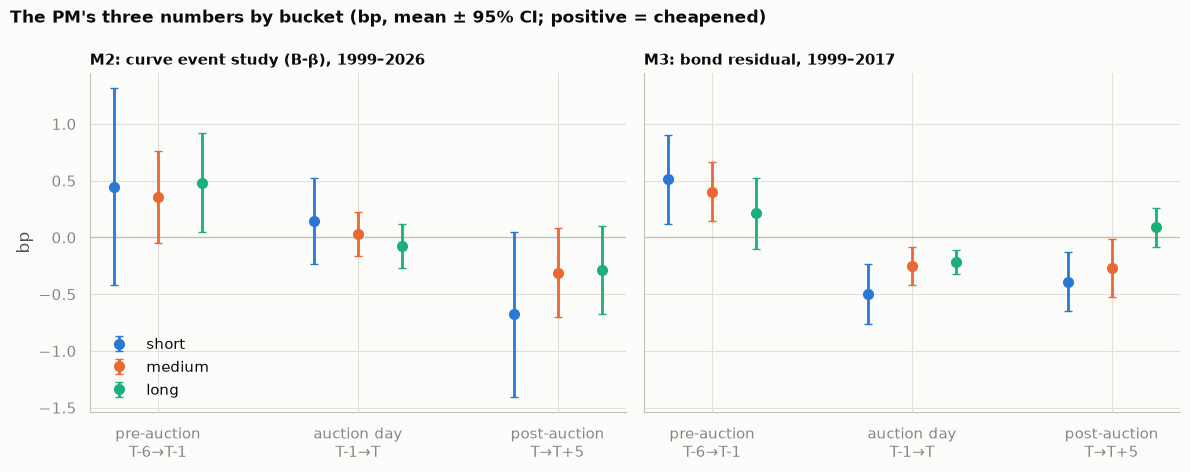

In [9]:
sets = [("M2 (B-β), all years", "M2: curve event study (B-β), 1999–2026"), ("M3, 1999-2017", "M3: bond residual, 1999–2017")]
order = an.BUCKETS
cb = plotting.colour_map(order)
wl = {"pre": "pre-auction\nT-6→T-1", "day": "auction day\nT-1→T", "post": "post-auction\nT→T+5"}
title = "The PM's three numbers by bucket (bp, mean ± 95% CI; positive = cheapened)"

fig_s, axes = plt.subplots(1, 2, figsize=(12, 4.8), sharey=True)
for ax, (s_, lab) in zip(axes, sets):
    t = H[(H["set"] == s_) & (H["by"] == "bucket")]
    ax.axhline(0, color=plotting.BASELINE, lw=1)
    for j, b in enumerate(order):
        u = t[t.group == b].set_index("measure").loc[an.WINDOWS]
        x = np.arange(3) + (j - 1) * 0.22
        ax.errorbar(x, u.mean_bp, yerr=1.96 * u.se_cluster, fmt="o", color=cb[b], ms=7, capsize=3, lw=2, label=b)
    ax.set_xticks(range(3), [wl[w] for w in an.WINDOWS])
    ax.set_title(lab, fontsize=11)
axes[0].set_ylabel("bp"); axes[0].legend(title=None, loc="lower left")
fig_s.suptitle(title, x=0.01, ha="left", fontweight="bold", fontsize=12)
fig_s.tight_layout()

fig_p = make_subplots(rows=1, cols=2, shared_yaxes=True, subplot_titles=[l for _, l in sets])
for c, (s_, lab) in enumerate(sets, start=1):
    t = H[(H["set"] == s_) & (H["by"] == "bucket")]
    for j, b in enumerate(order):
        u = t[t.group == b].set_index("measure").loc[an.WINDOWS]
        fig_p.add_trace(go.Scatter(x=[wl[w].replace("\n", " ") for w in an.WINDOWS], y=u.mean_bp, mode="markers",
                                   name=b, legendgroup=b, showlegend=(c == 1), marker=dict(color=cb[b], size=10),
                                   error_y=dict(type="data", array=1.96 * u.se_cluster, color=cb[b], thickness=2),
                                   customdata=np.stack([u.n, u.p_cluster], axis=1),
                                   hovertemplate=b + ": %{y:+.2f} bp<br>n %{customdata[0]:.0f}, p %{customdata[1]:.3f}<extra></extra>"),
                        row=1, col=c)
fig_p.add_hline(y=0, line_color=plotting.BASELINE)
fig_p.update_layout(template=plotting.PLOTLY_TEMPLATE, height=460, title=title, scattermode="group",
                    yaxis_title="bp", legend=dict(orientation="h", y=-0.2))
plotting.save_pair("stage5_three_numbers", fig_s, fig_p)
fig_p.show()

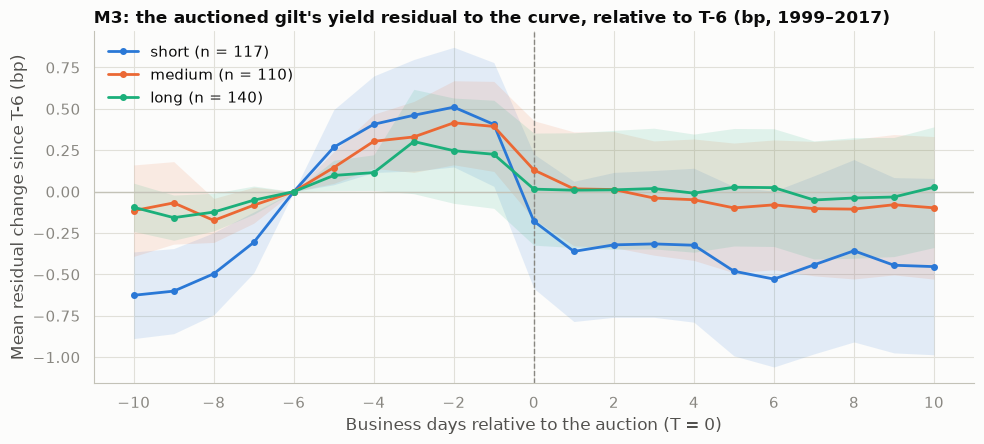

In [10]:
M3P = pd.read_csv(ms.M3_PATHS_FILE).merge(A[["auction_id", "bucket"]], on="auction_id")
M3P = M3P[M3P.groupby("auction_id")["residual_bp"].transform(lambda s: s.notna().all())]     # full paths only
agg = M3P.groupby(["bucket", "k"])["residual_rel_t6_bp"].agg(mean="mean", se=lambda s: s.std() / np.sqrt(len(s)), n="size").reset_index()
title = "M3: the auctioned gilt's yield residual to the curve, relative to T-6 (bp, 1999–2017)"
fig_s, ax = plt.subplots(figsize=(10, 4.6))
ax.axhline(0, color=plotting.BASELINE, lw=1); ax.axvline(0, color=plotting.INK_MUTED, lw=1, ls="--")
for b in order:
    a = agg[agg.bucket == b]
    ax.fill_between(a.k, a["mean"] - 1.96 * a.se, a["mean"] + 1.96 * a.se, color=cb[b], alpha=0.12, lw=0)
    ax.plot(a.k, a["mean"], color=cb[b], marker="o", ms=4, label=f"{b} (n = {int(a.n.iloc[0])})")
ax.set_xticks(range(-10, 11, 2)); ax.set_xlabel("Business days relative to the auction (T = 0)")
ax.set_ylabel("Mean residual change since T-6 (bp)"); ax.set_title(title); ax.legend(title=None, loc="upper left")
fig_s.tight_layout()
fig_p = go.Figure()
for b in order:
    a = agg[agg.bucket == b]
    r_, g_, b_ = (int(cb[b][i:i + 2], 16) for i in (1, 3, 5))
    fig_p.add_trace(go.Scatter(x=np.r_[a.k, a.k[::-1]], y=np.r_[a["mean"] + 1.96 * a.se, (a["mean"] - 1.96 * a.se)[::-1]],
                               fill="toself", fillcolor=f"rgba({r_},{g_},{b_},0.12)", line=dict(width=0),
                               hoverinfo="skip", showlegend=False, legendgroup=b))
    fig_p.add_trace(go.Scatter(x=a.k, y=a["mean"], mode="lines+markers", name=f"{b} (n = {int(a.n.iloc[0])})",
                               legendgroup=b, line=dict(color=cb[b]),
                               hovertemplate="T%{x:+d}: %{y:+.2f} bp<extra>" + b + "</extra>"))
fig_p.add_hline(y=0, line_color=plotting.BASELINE); fig_p.add_vline(x=0, line_dash="dash", line_color=plotting.INK_MUTED)
fig_p.update_layout(template=plotting.PLOTLY_TEMPLATE, height=440, title=title, xaxis_title="Business days relative to the auction (T = 0)",
                    yaxis_title="Mean residual change since T-6 (bp)", legend=dict(orientation="h", y=-0.2))
plotting.save_pair("stage5_m3_paths", fig_s, fig_p)
fig_p.show()

**Reading M2 against M3.**
- Both show the gilt cheapening into the auction (pre > 0).
- **They disagree on the day.**
  - M2 day is about zero. The gilt's own yield change, net of β × the far curve, is flat from T-1 to T.
  - M3 day is −0.32bp. On the day, the gilt richens relative to the fitted curve **at its own maturity**.
  - One reading: on auction day the whole sector around the auction maturity moves with the gilt. M3 removes that local move; M2's control (which excludes ±3y) does not.
- **Caveat on M3 (and M1).**
  - The BoE nominal curve is fitted to "conventional dated stocks with a significant amount in issue and having more than three months to maturity" ([BoE, further details about yields data](https://www.bankofengland.co.uk/statistics/details/further-details-about-yields-data)). So the auctioned gilt is itself one of the fitting points.
  - The spline partly follows the gilt's own move. Residual changes are therefore **attenuated towards zero**, more where few gilts sit nearby.
  - M2's control excludes ±3y around the gilt, so M2 does not have this problem.
- In the M3 paths, the short bucket's cheapening starts **before T-6**: −0.6bp at T-10 relative to T-6. The pre number (T-6→T-1) catches only part of it.

## 3. By regime

In [11]:
show("M2 (B-β), all years", "regime")

,group,measure,n,mean (bp),95% CI,p_cluster,p_nw,clusters
12,pre-crisis,pre,129.0,+1.13,"[+0.09, +2.16]",0.034,0.009,125.0
13,pre-crisis,day,129.0,-0.05,"[-0.56, +0.46]",0.849,0.833,125.0
14,pre-crisis,post,129.0,-0.88,"[-1.69, -0.07]",0.035,0.058,125.0
15,QE,pre,570.0,+0.59,"[+0.19, +0.98]",0.004,0.003,427.0
16,QE,day,570.0,-0.04,"[-0.21, +0.13]",0.636,0.623,427.0
17,QE,post,570.0,-0.62,"[-0.99, -0.25]",0.001,0.000,427.0
18,LDI stress,pre,3.0,-18.26,"[-43.21, +6.68]",0.387,0.001,2.0
19,LDI stress,day,3.0,+0.12,"[-19.44, +19.68]",0.992,0.979,2.0
20,LDI stress,post,3.0,+5.00,"[-9.96, +19.95]",0.631,0.134,2.0
21,active QT,pre,208.0,-0.16,"[-0.80, +0.48]",0.620,0.623,167.0


In [12]:
show("M3, 1999-2017", "regime")

,group,measure,n,mean (bp),95% CI,p_cluster,p_nw,clusters
36,pre-crisis,pre,118.0,+0.37,"[+0.13, +0.61]",0.003,0.027,114.0
37,pre-crisis,day,129.0,-0.41,"[-0.59, -0.24]",0.000,0.000,125.0
38,pre-crisis,post,129.0,-0.12,"[-0.29, +0.05]",0.171,0.207,125.0
39,QE,pre,277.0,+0.37,"[+0.12, +0.62]",0.004,0.019,247.0
40,QE,day,288.0,-0.28,"[-0.42, -0.14]",0.000,0.001,256.0
41,QE,post,287.0,-0.20,"[-0.38, -0.02]",0.028,0.026,255.0


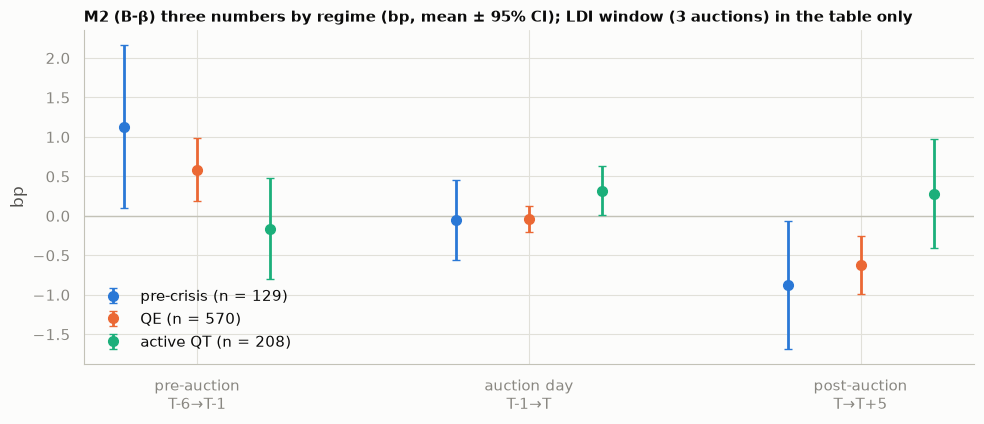

In [13]:
t = H[(H["set"] == "M2 (B-β), all years") & (H["by"] == "regime") & H.group.isin(["pre-crisis", "QE", "active QT"])]
regs = ["pre-crisis", "QE", "active QT"]
cr = plotting.colour_map(regs)
title = "M2 (B-β) three numbers by regime (bp, mean ± 95% CI); LDI window (3 auctions) in the table only"
fig_s, ax = plt.subplots(figsize=(10, 4.4))
ax.axhline(0, color=plotting.BASELINE, lw=1)
for j, g in enumerate(regs):
    u = t[t.group == g].set_index("measure").loc[an.WINDOWS]
    ax.errorbar(np.arange(3) + (j - 1) * 0.22, u.mean_bp, yerr=1.96 * u.se_cluster, fmt="o", color=cr[g], ms=7, capsize=3, lw=2,
                label=f"{g} (n = {int(u.n.iloc[0])})")
ax.set_xticks(range(3), [wl[w] for w in an.WINDOWS]); ax.set_ylabel("bp"); ax.set_title(title, fontsize=11)
ax.legend(title=None, loc="lower left"); fig_s.tight_layout()
fig_p = go.Figure()
for g in regs:
    u = t[t.group == g].set_index("measure").loc[an.WINDOWS]
    fig_p.add_trace(go.Scatter(x=[wl[w].replace("\n", " ") for w in an.WINDOWS], y=u.mean_bp, mode="markers", name=f"{g} (n = {int(u.n.iloc[0])})",
                               marker=dict(color=cr[g], size=10), error_y=dict(type="data", array=1.96 * u.se_cluster, color=cr[g], thickness=2),
                               hovertemplate=g + ": %{y:+.2f} bp<extra></extra>"))
fig_p.add_hline(y=0, line_color=plotting.BASELINE)
fig_p.update_layout(template=plotting.PLOTLY_TEMPLATE, height=420, title=title, scattermode="group", yaxis_title="bp",
                    legend=dict(orientation="h", y=-0.2))
plotting.save_pair("stage5_regimes", fig_s, fig_p)
fig_p.show()

## 4. Control C (gilt − OIS) against B-β, Dec 2021 onwards

In [14]:
RM = OUT["robust_means"]
t = RM[RM.variant.isin(["M2 B-β on the control-C sample (Dec 2021+)", "M2 control C (gilt - OIS, Dec 2021+)"])]
t.pivot_table(index=["group", "measure"], columns="variant", values="mean_bp", sort=False).round(2).join(
    t.pivot_table(index=["group", "measure"], columns="variant", values="p_cluster", sort=False).round(3), rsuffix=" p")

variant         M2 B-β on the control-C sample (Dec 2021+)  M2 control C (gilt - OIS, Dec 2021+)  M2 B-β on the control-C sample (Dec 2021+) p  M2 control C (gilt - OIS, Dec 2021+) p
group  measure                                                                                                                                                                        
all    pre                                           -0.16                                  0.48                                         0.687                                   0.139
       day                                            0.30                                 -0.06                                         0.139                                   0.698
       post                                           0.22                                  0.09                                         0.541                                   0.698
short  pre                                           -0.20                                  0.83                                         0.833                                   0.053
       day                                            0.43                                 -0.12                                         0.325                                   0.554
       post                                           0.16                                 -0.26                                         0.846                                   0.438
medium pre                                           -0.24                                  0.48                                         0.578                                   0.168
       day                                            0.25                                 -0.02                                         0.352                                   0.944
       post                                          -0.15                                  0.20                                         0.690                                   0.542
long   pre                                            0.01                                 -0.14                                         0.987                                   0.872
       day                                            0.17                                 -0.01                                         0.646                                   0.990
       post                                           0.88                                  0.53                                         0.217                                   0.359

## 5. Regressions (spec §8; decision #17)

Coefficient (clustered SE). Stars use the clustered p-value: *** 1%, ** 5%, * 10%.
- The base bucket is short. The base regime is pre-crisis, except in the 2018–2026 fixed-effects regression, where it is QE.
- The two post-QT-decision auctions are descriptive only and are left out.
- **Caveat:** cover and tail are auction outcomes. For the pre-auction window they are not known in advance.

In [15]:
OUT["regressions_wide"]

,M1b (1999-2017),"M1, gilt FE (2018-2026)",M2 pre (B-β),M2 day (B-β),M2 post (B-β),M3 pre,M3 day,M3 post,"M1 pooled, M1b sample"
const,+0.512 (0.968),-2.398 (2.168),+0.130 (0.967),-0.246 (0.374),-0.142 (0.728),-1.835** (0.862),+0.167 (0.230),-0.495* (0.265),+4.964*** (1.304)
dv01,+0.395 (0.321),+1.270** (0.515),-0.020 (0.229),-0.122 (0.092),-0.255 (0.182),+0.224 (0.243),+0.002 (0.082),+0.146 (0.092),-1.158** (0.548)
medium,-1.440* (0.740),-0.973 (1.334),+0.017 (0.552),+0.100 (0.230),+0.681 (0.460),-0.257 (0.336),+0.354** (0.173),-0.176 (0.215),-1.539 (1.092)
long,-1.559* (0.890),-3.685** (1.649),+0.036 (0.694),+0.076 (0.300),+1.143* (0.629),-0.561 (0.439),+0.189 (0.221),+0.107 (0.259),-2.416* (1.458)
cover_surprise,-1.536*** (0.591),+1.023 (0.823),+0.363 (0.664),-1.123*** (0.297),-0.213 (0.706),+0.136 (0.245),-0.574*** (0.165),-0.167 (0.206),-0.141 (1.021)
tail,+0.064 (0.256),-0.583 (0.646),+0.152 (0.648),+0.358 (0.244),-0.186 (0.259),+0.308 (0.236),+0.177 (0.130),-0.401*** (0.088),+0.852** (0.383)
new_issue,,+0.589 (0.843),+0.901 (0.689),-0.074 (0.337),+0.421 (0.571),+0.338 (0.347),+0.034 (0.207),-0.212 (0.250),
qt_week,,-2.255*** (0.810),+0.222 (0.908),+0.006 (0.349),+0.299 (0.827),,,,
qe_week,-0.108 (0.553),-0.875 (0.723),+0.082 (0.412),-0.099 (0.180),-0.146 (0.378),-0.007 (0.278),-0.022 (0.128),-0.072 (0.162),+0.629 (0.825)
synd_week,-0.889 (0.665),-0.513 (0.469),+0.309 (0.334),+0.101 (0.188),-0.421 (0.322),-0.263 (0.197),-0.064 (0.136),+0.085 (0.179),-1.426 (0.973)


**H4** (spec ⏳): adds long × post-2022 (from 1 Nov 2022) to the M1 fixed-effects and M2 regressions.

In [16]:
OUT["h4_wide"]

,"M1, gilt FE (2018-2026)",M2 pre (B-β),M2 day (B-β),M2 post (B-β)
const,-1.420 (2.058),+0.045 (0.955),-0.198 (0.370),-0.160 (0.721)
dv01,+0.922* (0.498),+0.103 (0.256),-0.190* (0.104),-0.228 (0.217)
medium,-0.702 (1.257),-0.116 (0.561),+0.174 (0.235),+0.652 (0.451)
long,-1.434 (1.768),-0.464 (0.857),+0.355 (0.370),+1.034 (0.739)
cover_surprise,+0.825 (0.815),+0.420 (0.673),-1.154*** (0.300),-0.200 (0.716)
tail,-0.735 (0.635),+0.173 (0.649),+0.347 (0.245),-0.181 (0.262)
new_issue,+0.775 (0.851),+0.891 (0.692),-0.068 (0.338),+0.419 (0.572)
qt_week,-2.106*** (0.777),+0.190 (0.911),+0.023 (0.349),+0.292 (0.829)
qe_week,-0.950 (0.717),+0.052 (0.415),-0.082 (0.182),-0.152 (0.381)
synd_week,-0.620 (0.471),+0.309 (0.335),+0.101 (0.187),-0.421 (0.322)


## 6. Placebo: 1,000 draws of non-auction dates (same gilt, same bucket)

In [17]:
PR = pd.read_csv(pl.OUT_DIR / "placebo_results.csv")
print("engine reproduces the real auctions to:", PR.groupby("measure").engine_check_max_abs.first().to_dict(),
      "| auctions without a placebo date:", PR.groupby("measure").no_placebo_date.first().to_dict())
pfmt = lambda p: "< 0.001" if p < 0.001 else f"{p:.3f}"     # 1,000 draws: the smallest attainable p is 0.001
t = PR[["measure", "group", "window", "n_events", "real_mean_bp", "placebo_mean_bp", "placebo_p2_5", "placebo_p97_5"]].round(3)
t["placebo p"] = PR["p_value"].map(pfmt)
t

engine reproduces the real auctions to: {'M2 (B-β)': 5.329070518200752e-14, 'M3': 6.923350781562475e-10} | auctions without a placebo date: {'M2 (B-β)': 15, 'M3': 3}


,measure,group,window,n_events,real_mean_bp,placebo_mean_bp,placebo_p2_5,placebo_p97_5,placebo p
0,M2 (B-β),all,pre,897,0.429,-0.065,-0.443,0.274,0.008
1,M2 (B-β),all,day,897,0.030,-0.045,-0.194,0.117,0.345
2,M2 (B-β),all,post,897,-0.451,-0.112,-0.504,0.242,0.074
3,M2 (B-β),short,pre,321,0.434,-0.074,-0.984,0.729,0.249
4,M2 (B-β),short,day,321,0.128,-0.091,-0.466,0.266,0.250
5,M2 (B-β),short,post,321,-0.696,-0.146,-0.973,0.714,0.198
6,M2 (B-β),medium,pre,277,0.363,-0.079,-0.505,0.375,0.053
7,M2 (B-β),medium,day,277,0.031,-0.052,-0.253,0.161,0.359
8,M2 (B-β),medium,post,277,-0.347,-0.180,-0.640,0.297,0.494
9,M2 (B-β),long,pre,299,0.484,-0.041,-0.395,0.348,0.004


**How to read the placebo.**
- Each draw replaces every real auction with a random non-auction date for the same gilt (same bucket) and recomputes the mean. The bars are 1,000 such means.
- The p-value is the share of draws at least as far from the placebo mean as the real mean.
- **The placebo centre is not zero for M2 (B-β).** The mean is −0.07bp (pre) and −0.11bp (post), because AR = Δy − βΔc has no intercept. Measured against that centre, the M2 post number weakens: p = 0.074 against 0.006 with clustered SEs.
- **The M3 placebo distribution is narrow.** Residual changes on ordinary days are much quieter than on auction days, so the real M3 numbers lie far outside it.
- With 1,000 draws, "< 0.001" means no draw was as extreme.

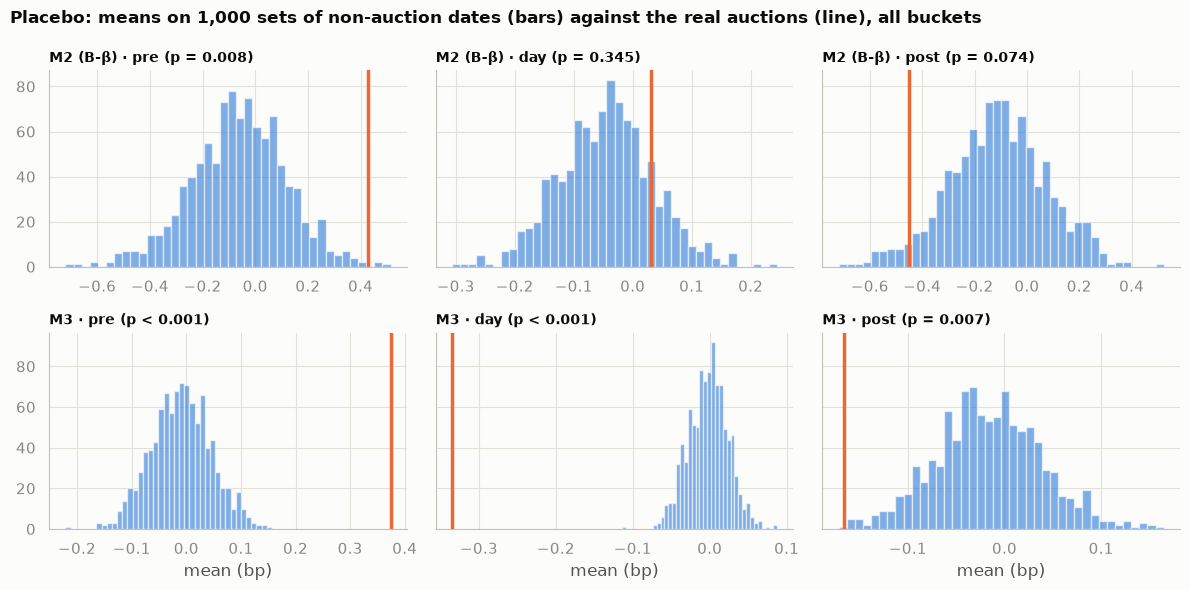

In [18]:
D = pd.read_csv(pl.OUT_DIR / "placebo_draws.csv.gz")
title = "Placebo: means on 1,000 sets of non-auction dates (bars) against the real auctions (line), all buckets"
cm = plotting.colour_map(["placebo", "real"])
fig_s, axes = plt.subplots(2, 3, figsize=(12, 6), sharey="row")
fig_p = make_subplots(rows=2, cols=3, subplot_titles=[f"{m} · {w}" for m in ["M2 (B-β)", "M3"] for w in an.WINDOWS])
for i, m in enumerate(["M2 (B-β)", "M3"]):
    for j, w in enumerate(an.WINDOWS):
        null = D[(D.measure == m) & (D.group == "all")][w]
        real = PR[(PR.measure == m) & (PR.group == "all") & (PR.window == w)]
        ax = axes[i, j]
        ax.hist(null, bins=40, color=cm["placebo"], alpha=0.6)
        ax.axvline(real.real_mean_bp.iloc[0], color=cm["real"], lw=2.5)
        p = real.p_value.iloc[0]
        ax.set_title(f"{m} · {w} (p {'< 0.001' if p < 0.001 else f'= {p:.3f}'})", fontsize=10)
        fig_p.add_trace(go.Histogram(x=null, nbinsx=40, marker_color=cm["placebo"], opacity=0.6, showlegend=False,
                                     hovertemplate="%{x:.2f} bp: %{y} draws<extra>placebo</extra>"), row=i + 1, col=j + 1)
        fig_p.add_vline(x=real.real_mean_bp.iloc[0], line_color=cm["real"], line_width=3, row=i + 1, col=j + 1)
for ax in axes[1]:
    ax.set_xlabel("mean (bp)")
fig_s.suptitle(title, x=0.01, ha="left", fontweight="bold", fontsize=12); fig_s.tight_layout()
fig_p.update_layout(template=plotting.PLOTLY_TEMPLATE, height=560, title=title)
plotting.save_pair("stage5_placebo", fig_s, fig_p)
fig_p.show()

## 7. Robustness

In [19]:
t = RM[RM.group == "all"].copy()
t["cell"] = [f"{m:+.2f} (p {p:.3f})" for m, p in zip(t.mean_bp, t.p_cluster)]
t.pivot_table(index="variant", columns="measure", values="cell", aggfunc="first", sort=False)[["pre", "day", "post", "level"]].fillna("")

measure,pre,day,post,level
variant,,,,
M2 B-β: main,+0.43 (p 0.012),+0.04 (p 0.634),-0.43 (p 0.006),
M2 B-β: drop LDI window,+0.49 (p 0.003),+0.04 (p 0.622),-0.45 (p 0.004),
M2 B-β: drop Feb-Oct 2022 (passive QT),+0.40 (p 0.016),+0.03 (p 0.703),-0.42 (p 0.006),
M2 B-β: drop > 5y beyond the curve,+0.41 (p 0.030),+0.08 (p 0.367),-0.40 (p 0.013),
M2 control B (β = 1),+0.40 (p 0.020),+0.02 (p 0.838),-0.49 (p 0.003),
M2 B-β on the control-C sample (Dec 2021+),-0.16 (p 0.687),+0.30 (p 0.139),+0.22 (p 0.541),
"M2 control C (gilt - OIS, Dec 2021+)",+0.48 (p 0.139),-0.06 (p 0.698),+0.09 (p 0.698),
M3: main,+0.37 (p 0.000),-0.32 (p 0.000),-0.18 (p 0.010),
M3: drop > 5y beyond the curve,+0.41 (p 0.000),-0.33 (p 0.000),-0.26 (p 0.000),


In [20]:
RR = OUT["robust_regressions"]
key = ["dv01", "cover_surprise", "tail", "vol", "QE", "active_QT"]
t = RR[RR.variable.isin(key) & RR.spec.isin(["M1b (1999-2017)", "M1, gilt FE (2018-2026)", "M2 day (B-β)", "M3 day"])].copy()
t["cell"] = [f"{c:+.2f}{'***' if p < .01 else '**' if p < .05 else '*' if p < .1 else ''}" for c, p in zip(t.coef, t.p_cluster)]
t.pivot_table(index=["spec", "variable"], columns="variant", values="cell", aggfunc="first", sort=False)

variant                                     main DV01 incl. PAOF volatility at 10y conventional-only syndications/tenders drop LDI window drop Feb-Oct 2022 drop > 5y beyond the curve
spec                    variable                                                                                                                                                      
M1b (1999-2017)         dv01               +0.39           +0.25             +0.42                                  +0.42           +0.39             +0.39                      +0.59
                        cover_surprise  -1.54***        -1.61***          -1.59***                                -1.53**        -1.54***          -1.54***                     -1.19*
                        tail               +0.06           +0.06             +0.04                                  +0.08           +0.06             +0.06                      +0.35
                        vol             +0.43***        +0.43***           +0.37**                               +0.44***        +0.43***          +0.43***                    +0.39**
                        QE              -1.69***        -1.69***          -1.91***                               -1.88***        -1.69***          -1.69***                   -1.66***
M1, gilt FE (2018-2026) dv01             +1.27**          +0.58*           +1.27**                                +1.26**         +1.28**           +1.21**                    +1.26**
                        cover_surprise     +1.02           +0.71             +0.97                                  +0.96           +1.00             +0.73                      +1.13
                        tail               -0.58           -0.52             -0.53                                  -0.58           -0.37             -0.47                      -0.59
                        vol               +0.14*           +0.12           +0.22**                                 +0.15*         +0.18**             +0.18                     +0.14*
                        active_QT       +6.29***         +6.02**          +6.28***                                +6.02**         +6.19**             +4.14                   +6.30***
M2 day (B-β)            dv01               -0.12           -0.11             -0.14                                  -0.11           -0.11             -0.10                      -0.11
                        cover_surprise  -1.12***        -1.11***          -1.07***                               -1.11***        -1.13***          -1.08***                   -0.93***
                        tail               +0.36           +0.35             +0.42                                  +0.36           +0.26             +0.33                      +0.63
                        vol                +0.03           +0.03             -0.03                                  +0.04           -0.01             +0.04                      +0.03
                        QE                 +0.23           +0.25             +0.28                                  +0.24           +0.26             +0.21                      +0.13
                        active_QT          +0.49           +0.51             +0.51                                  +0.57           +0.52             +0.33                      +0.40
M3 day                  dv01               +0.00           +0.02             -0.02                                  +0.00           +0.00             +0.00                      +0.09
                        cover_surprise  -0.57***        -0.57***          -0.56***                               -0.58***        -0.57***          -0.57***                   -0.62***
                        tail               +0.18           +0.18             +0.21                                  +0.18           +0.18             +0.18                      +0.28
                        vol             -0.21***        -0.20***          -0.19***                               -0.20***        -0.21***          -0.21***  

## 8. Checks on the machinery

- `inference.ols` reproduces statsmodels 0.15.0 to 1e-10: clustered (CR1) SEs, and Newey-West with equal spacing (`tests/test_stage5.py`). Clustered p-values use t with G − 1 degrees of freedom.
- The placebo engine recomputes M2 and M3 for the **real** auctions and matches the stored measures to < 1e-8 (§6).
- The market-yield method matches the DMO yields to 0.0001bp (§1).

## 9. Stopping here: the Stage 5 gate

The tables above are for your explain-back. **Choices to confirm** (⚑), each with the default used:
1. **Cover surprise:** bid-to-cover minus the mean of the previous **5** auctions in the same bucket.
2. **Supply controls** in the regressions: **dummies** (any syndication or tender within ±5 business days, including linkers), not counts.
3. **H4** "post-2022" = auctions from **1 Nov 2022** (active QT). It is an extra specification, not in the main table.
4. **Newey-West** bandwidth: **30 calendar days**, about one event window.
5. **Placebo design:** the same gilt on a random non-auction date in the same bucket, at least 10 business days from its own auctions, with ≥ 121 business days of history. Two-sided p-values are measured around the placebo mean. 15 auctions (M2) and 3 (M3) have no eligible date.
6. **Control C** beyond 25y: OIS extrapolated flat-forward (38 of the 241 auctions since Dec 2021 are > 25y).
7. **Regressions with outcomes on the right-hand side** (cover, tail), as listed in spec §8. Keep them, or move them to a separate "auction outcome" specification?
8. **LDI dummy:** 3 auctions in 2 clustered weeks. Its clustered SE is not reliable; the proposal is to report it but not interpret it. The same goes for the LDI row of the regime table.
9. **M3 attenuation:** the BoE curve is fitted to the auctioned gilt itself (§2). Note it as a limitation, or test it? A test could refit our own spline without the gilt, but that is a new curve build, so it would be a new decision.
10. **Placebo vs clustered SEs disagree for M2 post** (0.074 vs 0.006) because the placebo centre is not zero. Which inference leads in the write-up?